# Evaluación Segunda Unidad IA — CNN sobre CIFAR-10
Semilla individual: **69** (código 022100269G). Pruebas, EDA y visualización de muestras.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../src'))
import numpy as np, torch, matplotlib.pyplot as plt
from dataset import *
from model import CNN, validate_shapes
set_seed(SEED)
print('Semilla:', SEED)

Semilla: 69


## 1. Carga, partición estratificada y DataLoaders

In [2]:
train_loader, val_loader, test_loader = get_dataloaders(batch_size=128)

Train: 45000 | Validacion: 5000 | Test: 10000
Batch de entrenamiento: X (128, 3, 32, 32) | y (128,)


## 2. Visualización de muestras (EDA)

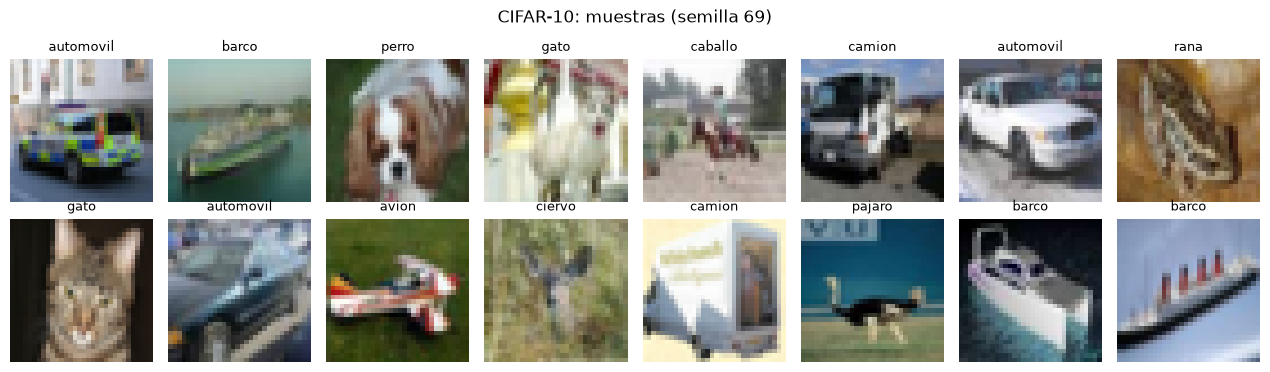

In [3]:
fig = show_samples(16)
plt.show()

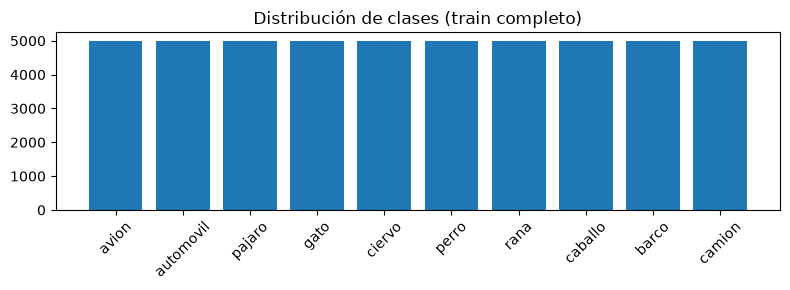

{'avion': np.int64(5000), 'automovil': np.int64(5000), 'pajaro': np.int64(5000), 'gato': np.int64(5000), 'ciervo': np.int64(5000), 'perro': np.int64(5000), 'rana': np.int64(5000), 'caballo': np.int64(5000), 'barco': np.int64(5000), 'camion': np.int64(5000)}


In [4]:
from torchvision import datasets
ds = datasets.CIFAR10(DATA_DIR, train=True)
counts = np.bincount(ds.targets)
plt.figure(figsize=(8,3)); plt.bar(CLASSES, counts); plt.xticks(rotation=45)
plt.title('Distribución de clases (train completo)'); plt.tight_layout(); plt.show()
print(dict(zip(CLASSES, counts)))

## 3. Efecto del Data Augmentation

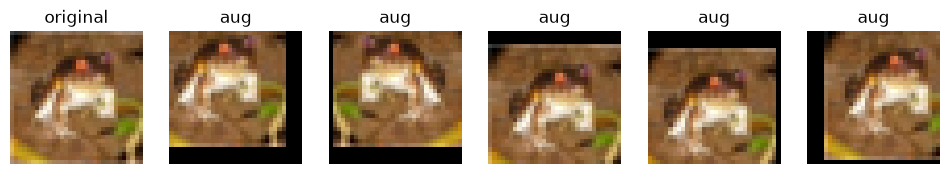

In [5]:
raw = datasets.CIFAR10(DATA_DIR, train=True)
train_tf, _ = get_transforms()
from torchvision import transforms
aug = transforms.Compose([t for t in train_tf.transforms if not isinstance(t, (transforms.ToTensor, transforms.Normalize))])
img, lab = raw[0]
fig, ax = plt.subplots(1, 6, figsize=(12, 2.4))
ax[0].imshow(img); ax[0].set_title('original')
for a in ax[1:]:
    a.imshow(aug(img)); a.set_title('aug')
for a in ax: a.axis('off')
plt.show()

## 4. Validación de shapes (tensor 4D)

In [6]:
validate_shapes(batch_size=8)

Entrada                 -> (8, 3, 32, 32)
Bloque 1 (Conv+ReLU+MP) -> (8, 32, 16, 16)
Bloque 2 (Conv+ReLU+MP) -> (8, 64, 8, 8)
Bloque 3 (Conv+ReLU+MP) -> (8, 128, 4, 4)
Flatten                 -> (8, 2048)
Linear -> logits        -> (8, 10)
OK: el modelo procesa tensores 4D sin Shape Mismatch.
Parametros entrenables: 620,362


## 5. Resultados del entrenamiento (`src/train.py`)

In [7]:
import json
m = json.load(open('../outputs/metrics.json'))
print(f"Test acc: {m['test_acc']:.4f} | Test loss: {m['test_loss']:.4f} | Mejor val acc: {m['best_val_acc']:.4f}")
print(f"Última época -> train acc {m['history']['train_acc'][-1]:.4f} | val acc {m['history']['val_acc'][-1]:.4f}")

Test acc: 0.8133 | Test loss: 0.5519 | Mejor val acc: 0.8242
Última época -> train acc 0.8106 | val acc 0.8104


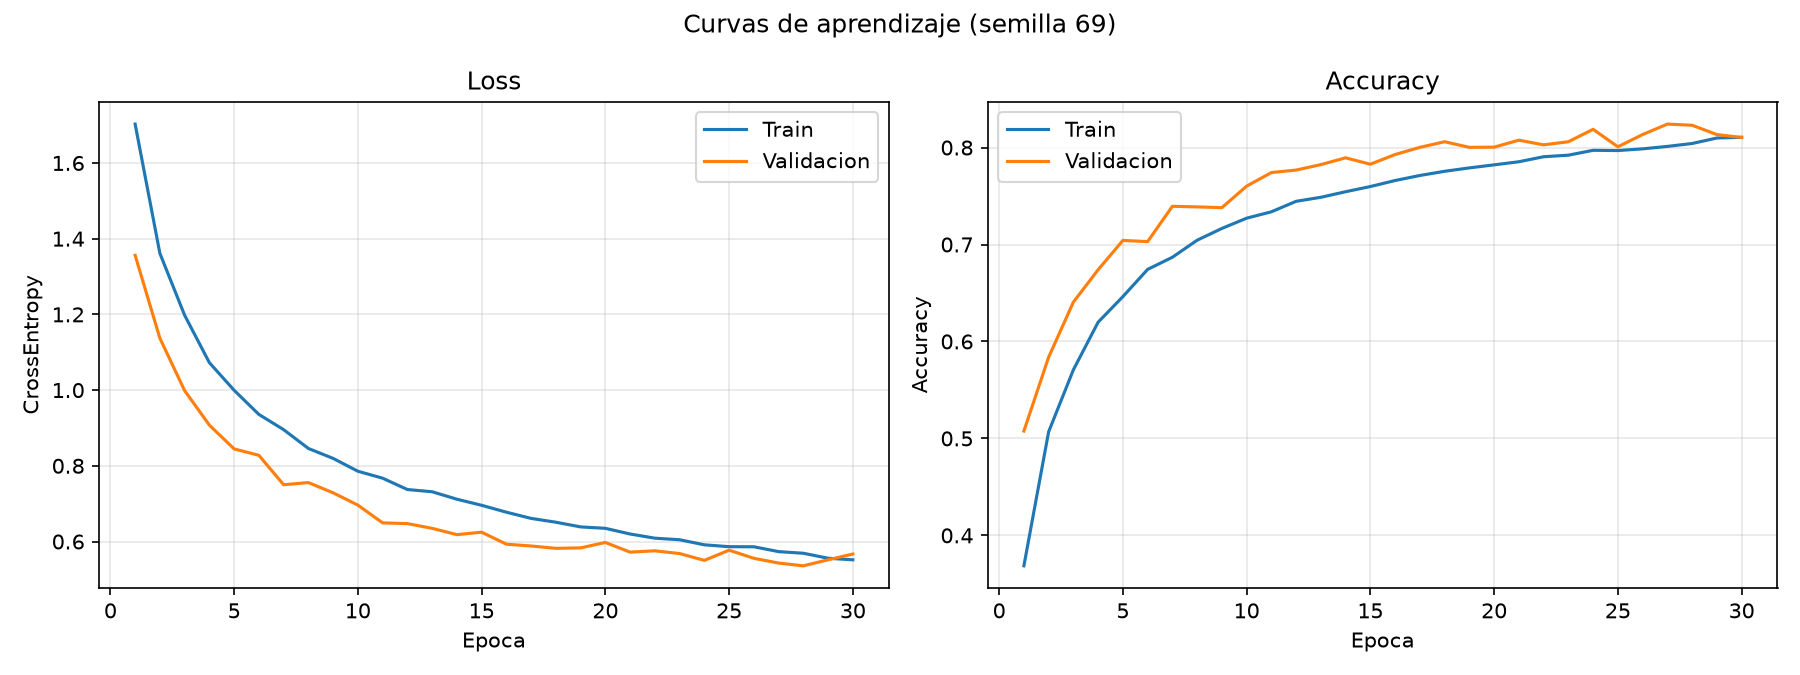

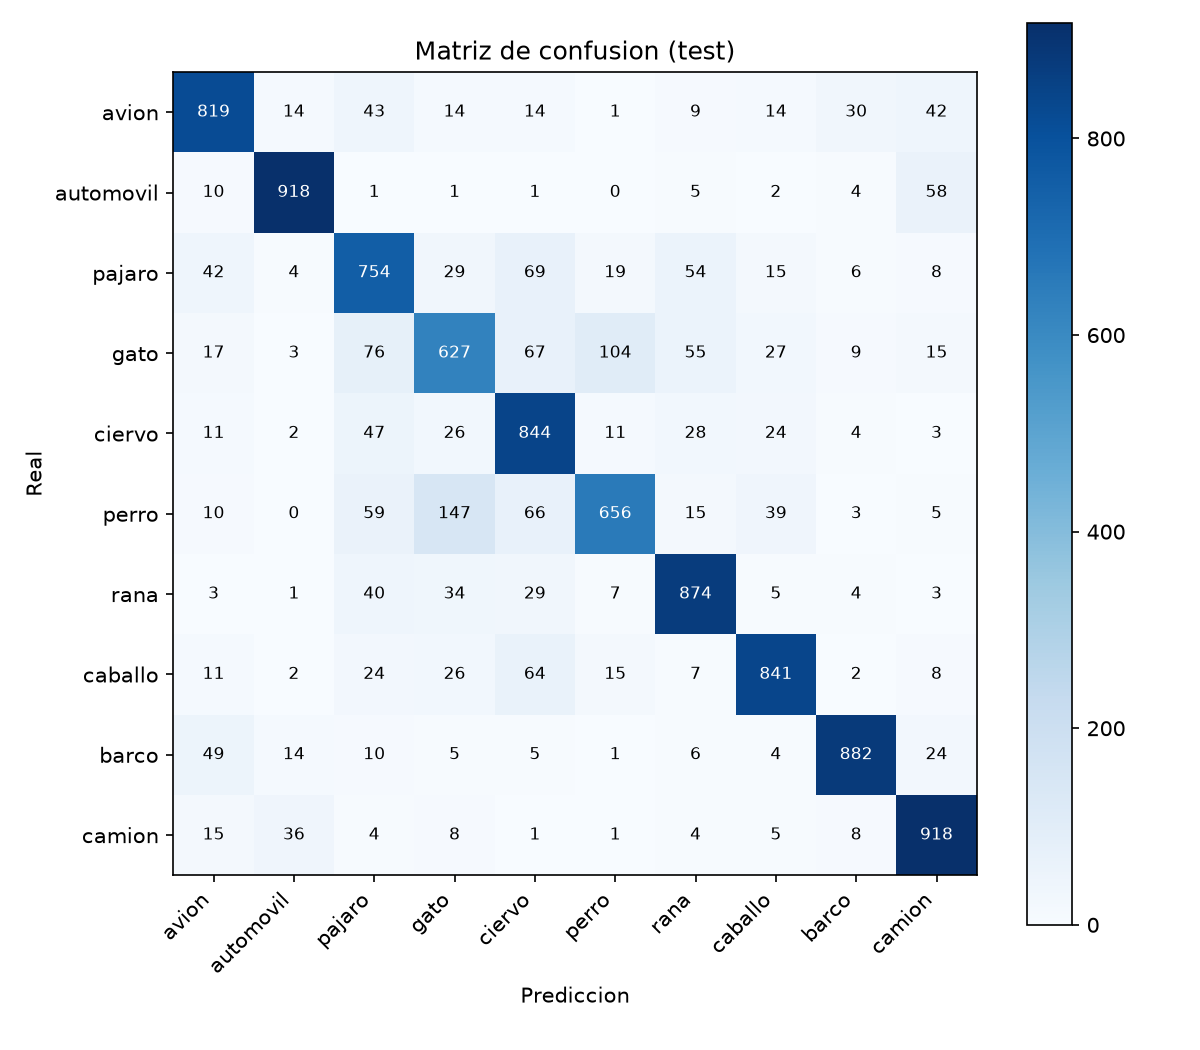

In [8]:
from IPython.display import Image, display
display(Image('../outputs/loss_accuracy.png')); display(Image('../outputs/confusion_matrix.png'))